In [2]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
bme_dir = '/projects/lindorff_group/people/thd711/HDXMS/code/'
sys.path.append(bme_dir)
from hdx_bme import HDXReweighter
from kint import *
import glob
from pathlib import Path
import math
import scipy.stats

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def calc_ccc(x, y):
    x = np.asarray(x)
    y = np.asarray(y)

    mx = np.mean(x)
    my = np.mean(y)
    vx = np.var(x, ddof=0)
    vy = np.var(y, ddof=0)
    sxy = np.cov(x, y, ddof=0)[0, 1]

    return 2 * sxy / (vx + vy + (mx - my) ** 2)


def find_elbow(x, y):
    # Convert to numpy arrays
    x = np.array(x)
    y = np.array(y)

    # Sort x (and y) if needed, but keep track of original indices
    if not np.all(np.diff(x) >= 0):
        idx_sort = np.argsort(x)
        x_sorted = x[idx_sort]
        y_sorted = y[idx_sort]
    else:
        idx_sort = np.arange(len(x))
        x_sorted, y_sorted = x, y

    # Line between first and last point
    p1 = np.array([x_sorted[0], y_sorted[0]])
    p2 = np.array([x_sorted[-1], y_sorted[-1]])
    line_vec = p2 - p1
    line_vec_norm = line_vec / np.linalg.norm(line_vec)

    # Distances from each point to the line
    vec_from_p1 = np.vstack([x_sorted - p1[0], y_sorted - p1[1]]).T
    proj_len = np.dot(vec_from_p1, line_vec_norm)
    proj_point = np.outer(proj_len, line_vec_norm) + p1
    dist = np.linalg.norm(vec_from_p1 - (proj_point - p1), axis=1)

    # Elbow = point with maximum distance
    idx_elbow_sorted = np.argmax(dist)
    idx_elbow_original = idx_sort[idx_elbow_sorted]

    return idx_elbow_original, x[idx_elbow_original], y[idx_elbow_original]

proteins = ['EEHEE_rd4_0871-No-His']


In [3]:
# gather all the data

path = '../BIOEMU_DATA/'

ntrajs = 10

phi_threshold = 0.1

data = {}

for protein in proteins:
    data[protein] = {}

    phis = np.loadtxt(path+protein+"/HDXrew_M14DH_scaled/phis.txt")
    chi2r = np.loadtxt(path+protein+"/HDXrew_M14DH_scaled/chi2r.txt")
    rmse = np.loadtxt(path+protein+"/HDXrew_M14DH_scaled/rmse.txt")
    wopt_array = np.load(path+protein+"/HDXrew_M14DH_scaled/wopt_array.npy")
    pred_array = np.load(path+protein+"/HDXrew_M14DH_scaled/pred_uptakes.npy")

    stop_idx= np.where(phis<phi_threshold)[0][0]
    print(stop_idx)
    phis = phis[:stop_idx]
    chi2r = chi2r[:stop_idx]
    rmse = rmse[:stop_idx]
    wopt_array = wopt_array[:stop_idx]
    pred_array = pred_array[:stop_idx]

    data[protein]['phi'] = phis
    data[protein]['chi2r'] = chi2r
    data[protein]['rmse'] = rmse
    data[protein]['wopt_array'] = wopt_array
    data[protein]['pred_array'] = pred_array

        

print('done')


27
done


14


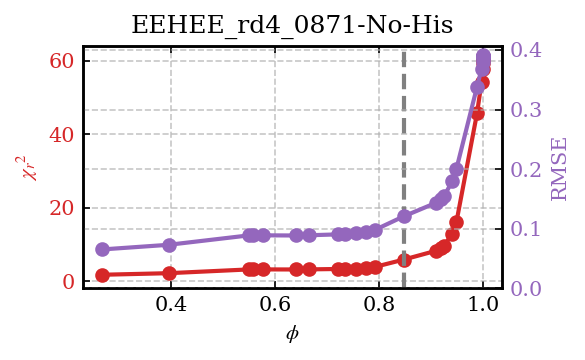

In [6]:


n_proteins = len(proteins)
ncols = 1
nrows = math.ceil(n_proteins / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(4, 2.5), sharex=False)

# Flatten axes array (works for any layout)
axes = np.array(axes).reshape(-1)

for ax, protein in zip(axes, proteins):
    phi = data[protein]['phi']
    chi2r = data[protein]['chi2r']
    rmse = data[protein]['rmse']

    # find elbow
    elidx, elx, ely = find_elbow(phi, rmse)
    elidx = elidx+1
    print(elidx)
    
    # Left axis
    ax.plot(phi, chi2r, 'o-', color='tab:red')
    ax.set_ylabel("$\chi$$_{r}$$^{2}$", color='tab:red')
    ax.tick_params(axis='y', labelcolor='tab:red')
    ax.axvline(phi[elidx], color = 'grey', linestyle='--')
    ax.set_title(protein)
    ax.set_xlabel("$\phi$")
    ax.set_ylim(-2,)
    
    # Right axis
    ax2 = ax.twinx()
    ax2.plot(phi, rmse, 'o-', color='tab:purple')
    ax2.set_ylabel("RMSE", color='tab:purple')
    ax2.tick_params(axis='y', labelcolor='tab:purple')
    ax2.set_ylim(0,)

# Hide unused subplots (if odd number of proteins)
for ax in axes[len(proteins):]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig('Lcurves.pdf', dpi=200)


In [4]:
chi2r

array([61.17752999, 60.98656492, 60.84244103, 60.58663377, 60.12630914,
       59.27713355, 57.63713167, 54.18193125, 45.63935799, 16.16532089,
       12.860736  ,  9.64972598,  8.90001463,  8.27746989,  5.83931184,
        3.87938581,  3.60415993,  3.39764509,  3.32004545,  3.27910121,
        3.17242206,  3.14707001,  3.16756065,  3.16380262,  3.16020014,
        2.13707336,  1.70264828])

In [5]:
rmse

array([0.39108033, 0.39046948, 0.39000782, 0.38918708, 0.38770578,
       0.38495822, 0.37959561, 0.36804188, 0.33778454, 0.2010306 ,
       0.17930934, 0.15532004, 0.14916446, 0.14385296, 0.12082334,
       0.09848078, 0.09492313, 0.09216351, 0.09110496, 0.09054144,
       0.08905647, 0.08869992, 0.08898821, 0.08893541, 0.08888476,
       0.07309366, 0.06524278])

In [6]:
phi

array([1.        , 0.99999746, 0.99999222, 0.99997599, 0.99992505,
       0.999761  , 0.99920738, 0.99716636, 0.98834005, 0.94886684,
       0.94024677, 0.92551325, 0.91954194, 0.91035931, 0.84730711,
       0.79274933, 0.77470292, 0.75623742, 0.73347062, 0.71989055,
       0.66401102, 0.63926585, 0.57697173, 0.55690859, 0.54922696,
       0.39462205, 0.26562033])

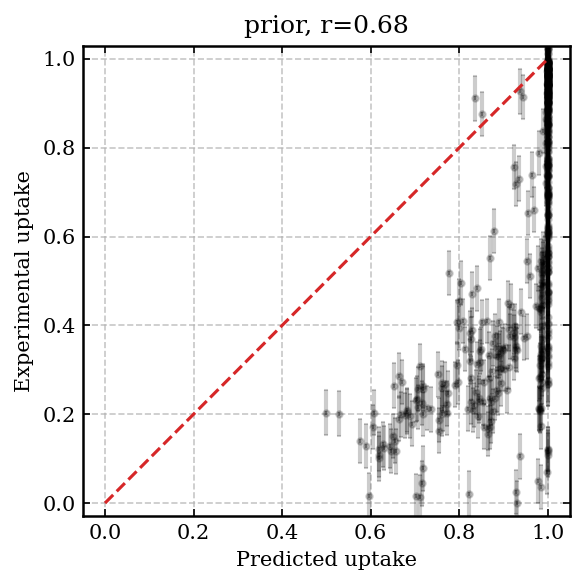

In [8]:
# plot uptake curves for prior and posterior compared to experiments (posterior picked based on automatic elbow picking)

protein=proteins[0]

plt.figure(figsize =(4,4))
phi = data[protein]['phi']
rmse = data[protein]['rmse']
pred_array = np.array(data[protein]['pred_array'])

# find elbow
elidx, elx, ely = find_elbow(phi, rmse)
elidx = elidx+1

# experimental uptake
exp_uptake = pd.read_csv(f'../EXP_DATA/{protein}.csv')

r = scipy.stats.pearsonr(pred_array[0], exp_uptake['Rel. Uptake'])[0]

plt.errorbar(pred_array[0], exp_uptake['Rel. Uptake'], xerr = np.zeros(len(pred_array[elidx])), yerr=exp_uptake['Rel. Uptake SD'], 
            fmt = 'o', color = 'black', capsize = 1, alpha=0.2, markersize=3)
plt.xlabel("Predicted uptake")
plt.ylabel("Experimental uptake")
plt.title(f'prior, r={r:.2f}')
plt.ylim(-0.03, 1.03)
plt.plot([0,1], [0,1], linestyle='--', color = 'tab:red', linewidth=1.5, zorder=30)



plt.tight_layout()
plt.savefig('uptakes_correlationplot_prior.png', dpi=200)


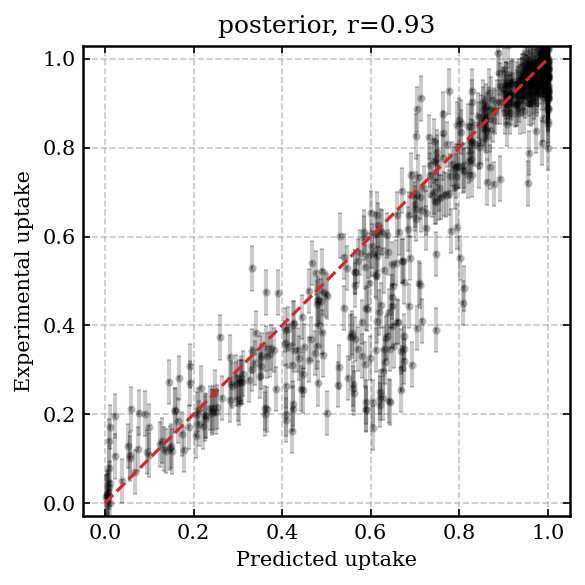

In [9]:
# plot uptake curves for prior and posterior compared to experiments (posterior picked based on automatic elbow picking)

protein=proteins[0]

plt.figure(figsize =(4,4))
phi = data[protein]['phi']
rmse = data[protein]['rmse']
pred_array = np.array(data[protein]['pred_array'])

# find elbow
elidx, elx, ely = find_elbow(phi, rmse)
elidx = elidx+1

# experimental uptake
exp_uptake = pd.read_csv(f'../EXP_DATA/{protein}.csv')

r = scipy.stats.pearsonr(pred_array[elidx], exp_uptake['Rel. Uptake'])[0]

plt.errorbar(pred_array[elidx], exp_uptake['Rel. Uptake'], xerr = np.zeros(len(pred_array[elidx])), yerr=exp_uptake['Rel. Uptake SD'], 
            fmt = 'o', color = 'black', capsize = 1, alpha=0.2, markersize=3)
plt.xlabel("Predicted uptake")
plt.ylabel("Experimental uptake")
plt.title(f'posterior, r={r:.2f}')
plt.ylim(-0.03, 1.03)
plt.plot([0,1], [0,1], linestyle='--', color = 'tab:red', linewidth=1.5, zorder=30)



plt.tight_layout()
plt.savefig('uptakes_correlationplot_posterior.png', dpi=200)


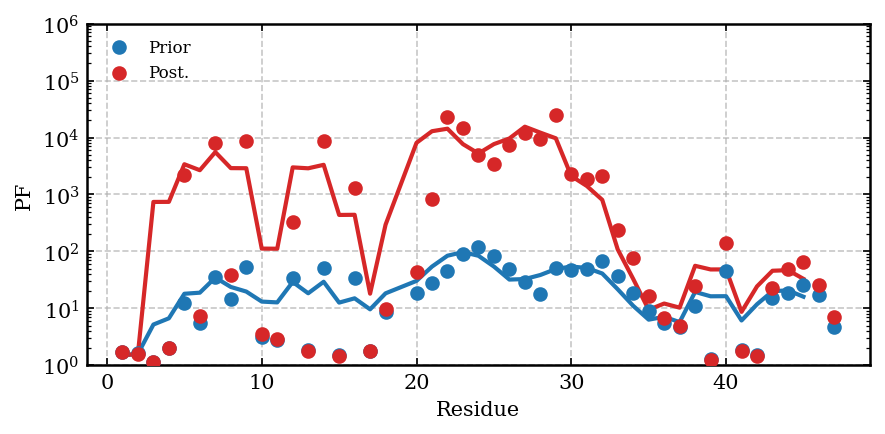

In [7]:
# plotting residue-specific protection factors before and after reweighting
res = np.loadtxt('../BIOEMU_DATA/EEHEE_rd4_0871-No-His/M14DH_scaled/amideresidues.txt').astype(int)
fopen = np.load('../BIOEMU_DATA/EEHEE_rd4_0871-No-His/M14DH_scaled/O.npy')
synframes=0
wopt = data['EEHEE_rd4_0871-No-His']['wopt_array'][elidx]

PF_prior = 1/np.mean(fopen, axis=0)
PF_post = 1/np.average(fopen, axis=0, weights=wopt[:len(wopt)-synframes])


plt.figure(figsize = (6,3))       

plt.scatter(res, PF_prior, color="tab:blue", label="Prior", zorder=20)
plt.scatter(res, PF_post, color="tab:red", label="Post.", zorder=20)

# moving average
x=res
y=PF_prior.copy()
y2=PF_post.copy()
window_size = 3  # adjust this for smoothing
kernel = np.ones(window_size) / window_size
# Moving average
y_smooth = np.convolve(y, kernel, mode='valid')
y2_smooth = np.convolve(y2, kernel, mode='valid')
# Adjust x to match the shorter length after convolution
x_smooth = x[:len(y_smooth)]
plt.plot(x_smooth, y_smooth, color='tab:blue',lw=2)
plt.plot(x_smooth, y2_smooth, color='tab:red',lw=2)


plt.ylabel('PF')
plt.xlabel('Residue')
plt.legend(loc='upper left', fontsize=8)
plt.yscale('log')
plt.ylim(1,1e6)

# highlight non-opened amides
closed = np.where(PF_post==np.inf)[0]
for ele in closed:
    plt.scatter(res[ele], 1/(1/len(wopt)), marker='x', color='black', s=25)



plt.tight_layout()
plt.savefig('residue_PFs.png')


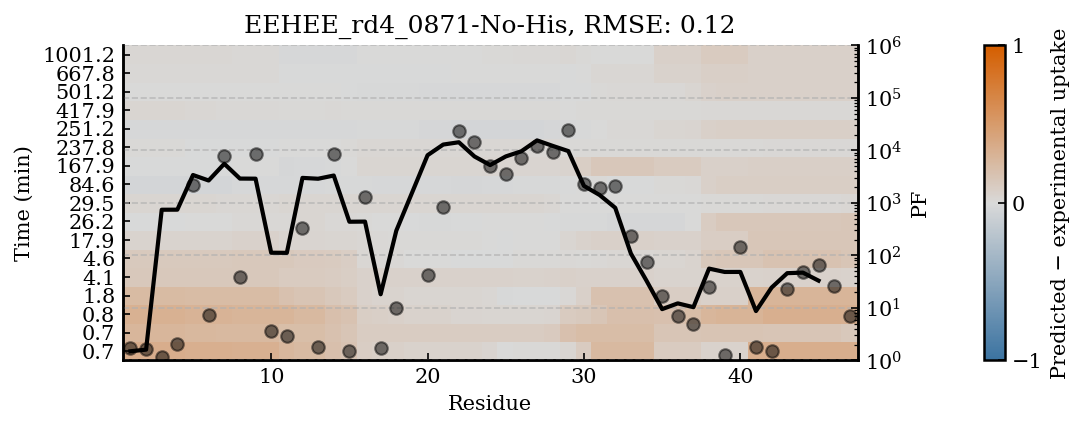

In [19]:
# plot posterior-experiment heatmap and PFs
from matplotlib.colors import LinearSegmentedColormap
protein = 'EEHEE_rd4_0871-No-His'

# ------------------------------------------------------------------
# Get posterior corresponding to automatically picked elbow
# ------------------------------------------------------------------

phi = data[protein]['phi']
rmse = data[protein]['rmse']
pred_array = np.array(data[protein]['pred_array'])

elidx, elx, ely = find_elbow(phi, rmse)
elidx = elidx + 1

# ------------------------------------------------------------------
# Experimental uptake + predicted - experimental difference
# pred_array is assumed to be in the same row order as the CSV
# ------------------------------------------------------------------

exp_uptake = pd.read_csv(f'../EXP_DATA/{protein}.csv')
exp_uptake['Difference'] = pred_array[elidx] - exp_uptake['Rel. Uptake']

# colour scale: -1 -> 0 -> +1
cmap = LinearSegmentedColormap.from_list('difference_cmap', [(0.0, "#3B73A1"), (0.5, "#D9D9D9"), (1.0, "#D55E00")])

# ------------------------------------------------------------------
# Build residue x time matrix
# Each peptide contributes its predicted - experimental difference
# to every residue it covers.
# Overlapping peptides are averaged at each residue/time point.
# ------------------------------------------------------------------

times = np.sort(exp_uptake['Time (s)'].dropna().unique())
times_min = np.round(times / 60, 1)
residues = np.arange(int(exp_uptake['Start'].min()), int(exp_uptake['End'].max()) + 1)

difference = np.full((len(times), len(residues)), np.nan)

for i, t in enumerate(times):
    df_t = exp_uptake[exp_uptake['Time (s)'] == t]
    for j, resi in enumerate(residues):
        vals = df_t.loc[(df_t['Start'] <= resi) & (df_t['End'] >= resi), 'Difference'].values
        if len(vals) > 0:
            difference[i, j] = np.nanmean(vals)

# ------------------------------------------------------------------
# Calculate posterior ensemble-averaged protection factors
# ------------------------------------------------------------------

res = np.loadtxt(f'../BIOEMU_DATA/{protein}/M14DH_scaled/amideresidues.txt').astype(int)
fopen = np.load(f'../BIOEMU_DATA/{protein}/M14DH_scaled/O.npy')

synframes = 0
wopt = data[protein]['wopt_array'][elidx]

PF_post = 1 / np.average(fopen, axis=0, weights=wopt[:len(wopt)-synframes])

# moving average
window_size = 3
kernel = np.ones(window_size) / window_size
PF_post_smooth = np.convolve(PF_post, kernel, mode='valid')
res_smooth = res[:len(PF_post_smooth)]

# ------------------------------------------------------------------
# Cell edges for pcolormesh
# ------------------------------------------------------------------

x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)
y_edges = np.arange(len(times) + 1)

# ------------------------------------------------------------------
# Plot
# Keep heatmap itself the same width as in the original heatmap
# ------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 3))

im = ax.pcolormesh(x_edges, y_edges, difference, cmap=cmap, vmin=-1, vmax=1, shading='flat', rasterized=True)

ax.set_xlabel('Residue')
ax.set_ylabel('Time (min)')
ax.set_title(protein + str(f', RMSE: {rmse[elidx]:.2f}'))

ax.set_yticks(np.arange(len(times)) + 0.5)
ax.set_yticklabels([f'{t:.1f}' for t in times_min])

ax.tick_params(top=False, right=False)
ax.spines['top'].set_visible(False)

# ------------------------------------------------------------------
# Protection factors on right y-axis
# ------------------------------------------------------------------

ax2 = ax.twinx()

ax2.scatter(res, PF_post, color='black', alpha=0.5, zorder=20)
ax2.plot(res_smooth, PF_post_smooth, color='black', lw=2, zorder=21)

ax2.set_ylabel('PF')
ax2.set_yscale('log')
ax2.set_ylim(1, 1e6)
ax2.tick_params(top=False)
ax2.spines['top'].set_visible(False)

# ------------------------------------------------------------------
# Match original heatmap plotting width and add colorbar outside it
# ------------------------------------------------------------------

plt.subplots_adjust(left=0.12, right=0.82, bottom=0.18, top=0.88)

cax = fig.add_axes([0.94, 0.18, 0.02, 0.70])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Predicted − experimental uptake')
cbar.set_ticks([-1, 0, 1])

plt.savefig(f'{protein}_uptake_difference_heatmap_PF_post1.pdf', dpi=300, bbox_inches='tight')
plt.show()

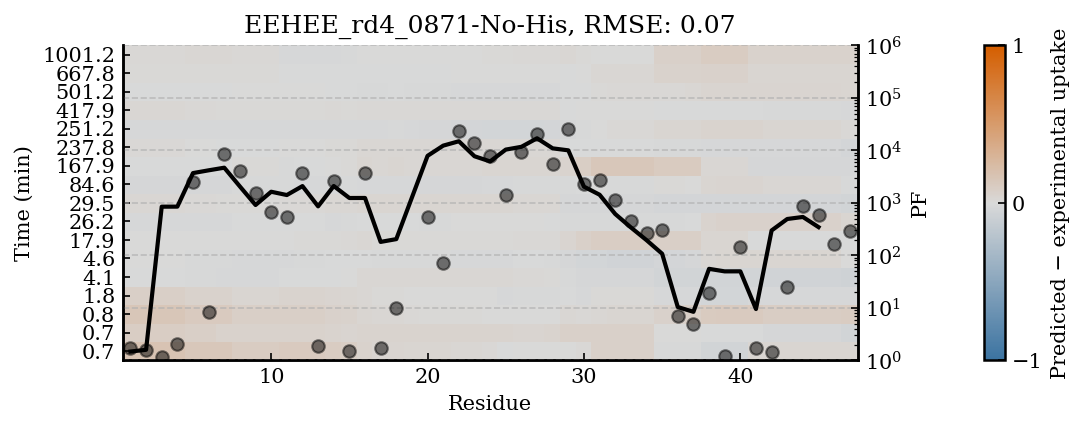

In [20]:
# plot posterior-experiment heatmap and PFs
from matplotlib.colors import LinearSegmentedColormap
protein = 'EEHEE_rd4_0871-No-His'

# ------------------------------------------------------------------
# Get posterior corresponding to automatically picked elbow
# ------------------------------------------------------------------

phi = data[protein]['phi']
rmse = data[protein]['rmse']
pred_array = np.array(data[protein]['pred_array'])

elidx=-1 # last reweighting result with phi>0.1

# ------------------------------------------------------------------
# Experimental uptake + predicted - experimental difference
# pred_array is assumed to be in the same row order as the CSV
# ------------------------------------------------------------------

exp_uptake = pd.read_csv(f'../EXP_DATA/{protein}.csv')
exp_uptake['Difference'] = pred_array[elidx] - exp_uptake['Rel. Uptake']

# colour scale: -1 -> 0 -> +1
cmap = LinearSegmentedColormap.from_list('difference_cmap', [(0.0, "#3B73A1"), (0.5, "#D9D9D9"), (1.0, "#D55E00")])

# ------------------------------------------------------------------
# Build residue x time matrix
# Each peptide contributes its predicted - experimental difference
# to every residue it covers.
# Overlapping peptides are averaged at each residue/time point.
# ------------------------------------------------------------------

times = np.sort(exp_uptake['Time (s)'].dropna().unique())
times_min = np.round(times / 60, 1)
residues = np.arange(int(exp_uptake['Start'].min()), int(exp_uptake['End'].max()) + 1)

difference = np.full((len(times), len(residues)), np.nan)

for i, t in enumerate(times):
    df_t = exp_uptake[exp_uptake['Time (s)'] == t]
    for j, resi in enumerate(residues):
        vals = df_t.loc[(df_t['Start'] <= resi) & (df_t['End'] >= resi), 'Difference'].values
        if len(vals) > 0:
            difference[i, j] = np.nanmean(vals)

# ------------------------------------------------------------------
# Calculate posterior ensemble-averaged protection factors
# ------------------------------------------------------------------

res = np.loadtxt(f'../BIOEMU_DATA/{protein}/M14DH_scaled/amideresidues.txt').astype(int)
fopen = np.load(f'../BIOEMU_DATA/{protein}/M14DH_scaled/O.npy')

synframes = 0
wopt = data[protein]['wopt_array'][elidx]

PF_post = 1 / np.average(fopen, axis=0, weights=wopt[:len(wopt)-synframes])

# moving average
window_size = 3
kernel = np.ones(window_size) / window_size
PF_post_smooth = np.convolve(PF_post, kernel, mode='valid')
res_smooth = res[:len(PF_post_smooth)]

# ------------------------------------------------------------------
# Cell edges for pcolormesh
# ------------------------------------------------------------------

x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)
y_edges = np.arange(len(times) + 1)

# ------------------------------------------------------------------
# Plot
# Keep heatmap itself the same width as in the original heatmap
# ------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 3))

im = ax.pcolormesh(x_edges, y_edges, difference, cmap=cmap, vmin=-1, vmax=1, shading='flat', rasterized=True)

ax.set_xlabel('Residue')
ax.set_ylabel('Time (min)')
ax.set_title(protein + str(f', RMSE: {rmse[elidx]:.2f}'))

ax.set_yticks(np.arange(len(times)) + 0.5)
ax.set_yticklabels([f'{t:.1f}' for t in times_min])

ax.tick_params(top=False, right=False)
ax.spines['top'].set_visible(False)

# ------------------------------------------------------------------
# Protection factors on right y-axis
# ------------------------------------------------------------------

ax2 = ax.twinx()

ax2.scatter(res, PF_post, color='black', alpha=0.5, zorder=20)
ax2.plot(res_smooth, PF_post_smooth, color='black', lw=2, zorder=21)

ax2.set_ylabel('PF')
ax2.set_yscale('log')
ax2.set_ylim(1, 1e6)
ax2.tick_params(top=False)
ax2.spines['top'].set_visible(False)

# ------------------------------------------------------------------
# Match original heatmap plotting width and add colorbar outside it
# ------------------------------------------------------------------

plt.subplots_adjust(left=0.12, right=0.82, bottom=0.18, top=0.88)

cax = fig.add_axes([0.94, 0.18, 0.02, 0.70])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Predicted − experimental uptake')
cbar.set_ticks([-1, 0, 1])

plt.savefig(f'{protein}_uptake_difference_heatmap_PF_post2.pdf', dpi=300, bbox_inches='tight')
plt.show()

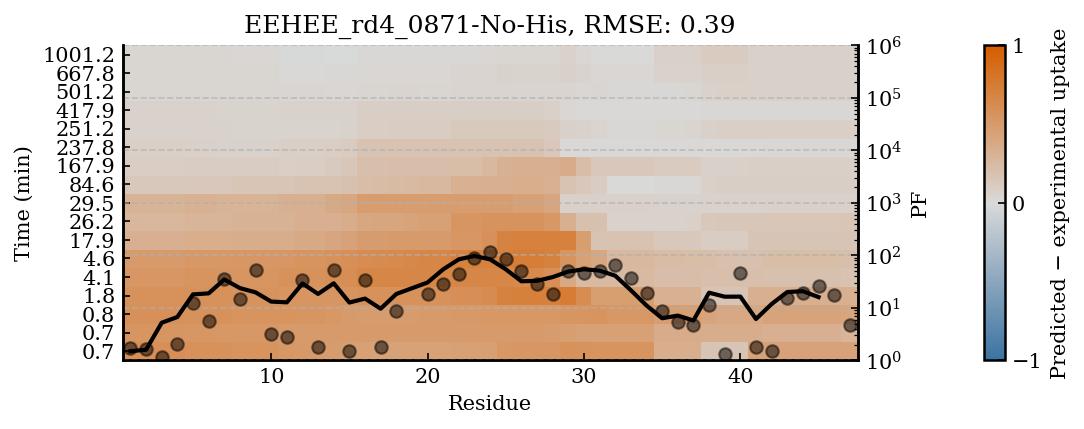

In [21]:
# plot prior-experiment heatmap and PFs
from matplotlib.colors import LinearSegmentedColormap
protein = 'EEHEE_rd4_0871-No-His'

# ------------------------------------------------------------------
# Get posterior corresponding to automatically picked elbow
# ------------------------------------------------------------------

phi = data[protein]['phi']
rmse = data[protein]['rmse']
pred_array = np.array(data[protein]['pred_array'])

elidx = 0 # prior

# ------------------------------------------------------------------
# Experimental uptake + predicted - experimental difference
# pred_array is assumed to be in the same row order as the CSV
# ------------------------------------------------------------------

exp_uptake = pd.read_csv(f'../EXP_DATA/{protein}.csv')
exp_uptake['Difference'] = pred_array[elidx] - exp_uptake['Rel. Uptake']

# colour scale: -1 -> 0 -> +1
cmap = LinearSegmentedColormap.from_list('difference_cmap', [(0.0, "#3B73A1"), (0.5, "#D9D9D9"), (1.0, "#D55E00")])

# ------------------------------------------------------------------
# Build residue x time matrix
# Each peptide contributes its predicted - experimental difference
# to every residue it covers.
# Overlapping peptides are averaged at each residue/time point.
# ------------------------------------------------------------------

times = np.sort(exp_uptake['Time (s)'].dropna().unique())
times_min = np.round(times / 60, 1)
residues = np.arange(int(exp_uptake['Start'].min()), int(exp_uptake['End'].max()) + 1)

difference = np.full((len(times), len(residues)), np.nan)

for i, t in enumerate(times):
    df_t = exp_uptake[exp_uptake['Time (s)'] == t]
    for j, resi in enumerate(residues):
        vals = df_t.loc[(df_t['Start'] <= resi) & (df_t['End'] >= resi), 'Difference'].values
        if len(vals) > 0:
            difference[i, j] = np.nanmean(vals)

# ------------------------------------------------------------------
# Calculate posterior ensemble-averaged protection factors
# ------------------------------------------------------------------

res = np.loadtxt(f'../BIOEMU_DATA/{protein}/M14DH_scaled/amideresidues.txt').astype(int)
fopen = np.load(f'../BIOEMU_DATA/{protein}/M14DH_scaled/O.npy')

synframes = 0
wopt = data[protein]['wopt_array'][elidx]

PF_post = 1 / np.average(fopen, axis=0, weights=wopt[:len(wopt)-synframes])

# moving average
window_size = 3
kernel = np.ones(window_size) / window_size
PF_post_smooth = np.convolve(PF_post, kernel, mode='valid')
res_smooth = res[:len(PF_post_smooth)]

# ------------------------------------------------------------------
# Cell edges for pcolormesh
# ------------------------------------------------------------------

x_edges = np.arange(residues[0] - 0.5, residues[-1] + 1.5, 1)
y_edges = np.arange(len(times) + 1)

# ------------------------------------------------------------------
# Plot
# Keep heatmap itself the same width as in the original heatmap
# ------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 3))

im = ax.pcolormesh(x_edges, y_edges, difference, cmap=cmap, vmin=-1, vmax=1, shading='flat', rasterized=True)

ax.set_xlabel('Residue')
ax.set_ylabel('Time (min)')
ax.set_title(protein + str(f', RMSE: {rmse[elidx]:.2f}'))

ax.set_yticks(np.arange(len(times)) + 0.5)
ax.set_yticklabels([f'{t:.1f}' for t in times_min])

ax.tick_params(top=False, right=False)
ax.spines['top'].set_visible(False)

# ------------------------------------------------------------------
# Protection factors on right y-axis
# ------------------------------------------------------------------

ax2 = ax.twinx()

ax2.scatter(res, PF_post, color='black', alpha=0.5, zorder=20)
ax2.plot(res_smooth, PF_post_smooth, color='black', lw=2, zorder=21)

ax2.set_ylabel('PF')
ax2.set_yscale('log')
ax2.set_ylim(1, 1e6)
ax2.tick_params(top=False)
ax2.spines['top'].set_visible(False)

# ------------------------------------------------------------------
# Match original heatmap plotting width and add colorbar outside it
# ------------------------------------------------------------------

plt.subplots_adjust(left=0.12, right=0.82, bottom=0.18, top=0.88)

cax = fig.add_axes([0.94, 0.18, 0.02, 0.70])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Predicted − experimental uptake')
cbar.set_ticks([-1, 0, 1])

plt.savefig(f'{protein}_uptake_difference_heatmap_PF_prior.pdf', dpi=300, bbox_inches='tight')
plt.show()

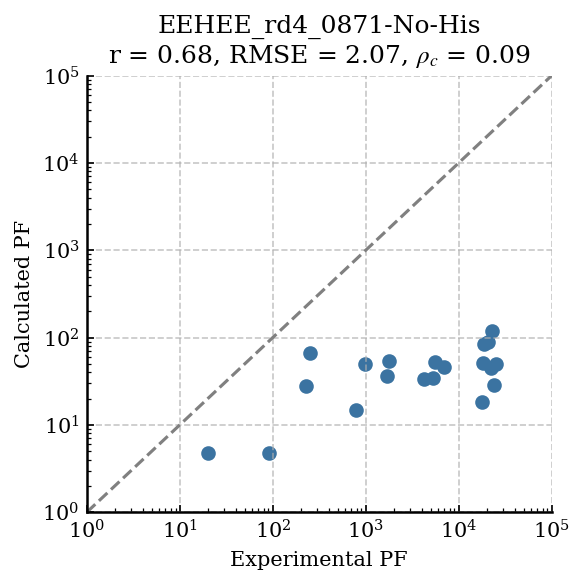

In [75]:
protein = 'EEHEE_rd4_0871-No-His'
model = 'M14DH_scaled'

# load open/closed matrix and corresponding amide residue numbers
res = np.loadtxt(f'../BIOEMU_DATA/{protein}/{model}/amideresidues.txt').astype(int)
fopen = np.load(f'../BIOEMU_DATA/{protein}/{model}/O.npy')

# ensemble-averaged protection factors
PF_calc = 1 / np.mean(fopen, axis=0)
PF_calc = np.minimum(PF_calc, fopen.shape[0])  # lower bound for amides that never open

# experimental NMR protection factors
exp_pf = pd.read_csv(f'../../HDX_project/EXP_DATA/PF_Stofella_2025/{protein}.csv')

# match calculated and experimental PFs by residue number
calc_df = pd.DataFrame({'Model_residue': res, 'PF_calc': PF_calc})
matched = exp_pf[['Model_residue', 'PF']].merge(calc_df, on='Model_residue', how='inner').dropna()

# statistics in log10 space
x = np.log10(matched['PF'].values)
y = np.log10(matched['PF_calc'].values)

r = scipy.stats.pearsonr(x, y)[0]
rmse = np.sqrt(np.mean((y - x)**2))
rho_c = calc_ccc(x, y)

# plot
plt.figure(figsize=(4, 4))

plt.scatter(matched['PF'], matched['PF_calc'], color='#3B73A1', alpha=1.0)

lims = [1e0,1e5]
plt.plot(lims, lims, '--', color='grey', lw=1.5)

plt.xscale('log')
plt.yscale('log')
plt.xlim(lims)
plt.ylim(lims)

plt.xlabel('Experimental PF')
plt.ylabel('Calculated PF')
plt.title(f'{protein}\nr = {r:.2f}, RMSE = {rmse:.2f}, $\\rho_c$ = {rho_c:.2f}')

ax = plt.gca()
ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(f'{protein}_{model}_NMR_PF_correlation_prior.pdf', dpi=300)
plt.show()

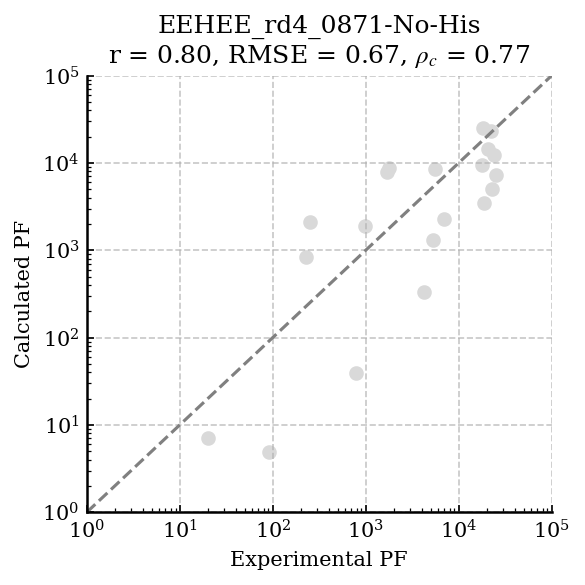

In [76]:
protein = 'EEHEE_rd4_0871-No-His'
model = 'M14DH_scaled'

# load open/closed matrix and corresponding amide residue numbers
res = np.loadtxt(f'../BIOEMU_DATA/{protein}/{model}/amideresidues.txt').astype(int)
fopen = np.load(f'../BIOEMU_DATA/{protein}/{model}/O.npy')

phi = data[protein]['phi']
rmse = data[protein]['rmse']
pred_array = np.array(data[protein]['pred_array'])

elidx, elx, ely = find_elbow(phi, rmse)
elidx = elidx + 1
wopt = data[protein]['wopt_array'][elidx]

# ensemble-averaged protection factors
PF_calc = 1 / np.average(fopen, axis=0, weights=wopt)
PF_calc = np.minimum(PF_calc, fopen.shape[0])  # lower bound for amides that never open

# experimental NMR protection factors
exp_pf = pd.read_csv(f'../../HDX_project/EXP_DATA/PF_Stofella_2025/{protein}.csv')

# match calculated and experimental PFs by residue number
calc_df = pd.DataFrame({'Model_residue': res, 'PF_calc': PF_calc})
matched = exp_pf[['Model_residue', 'PF']].merge(calc_df, on='Model_residue', how='inner').dropna()

# statistics in log10 space
x = np.log10(matched['PF'].values)
y = np.log10(matched['PF_calc'].values)

r = scipy.stats.pearsonr(x, y)[0]
rmse = np.sqrt(np.mean((y - x)**2))
rho_c = calc_ccc(x, y)

# plot
plt.figure(figsize=(4, 4))

plt.scatter(matched['PF'], matched['PF_calc'], color='#D9D9D9', alpha=1.0)

lims = [1e0,1e5]
plt.plot(lims, lims, '--', color='grey', lw=1.5)

plt.xscale('log')
plt.yscale('log')
plt.xlim(lims)
plt.ylim(lims)

plt.xlabel('Experimental PF')
plt.ylabel('Calculated PF')
plt.title(f'{protein}\nr = {r:.2f}, RMSE = {rmse:.2f}, $\\rho_c$ = {rho_c:.2f}')

ax = plt.gca()
ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(f'{protein}_{model}_NMR_PF_correlation_post1.pdf', dpi=300)
plt.show()

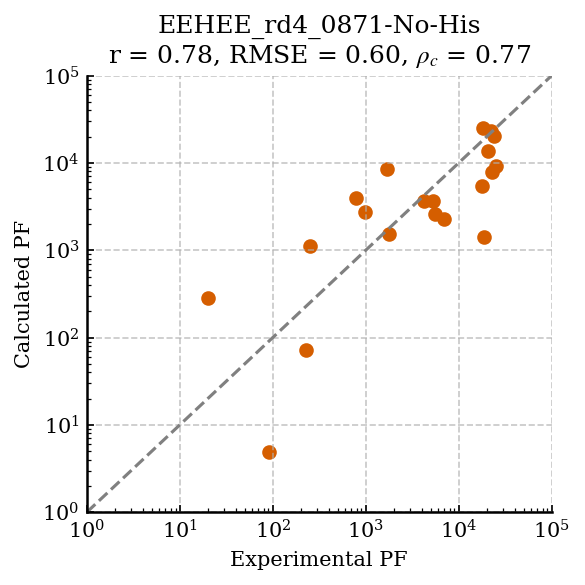

In [82]:
protein = 'EEHEE_rd4_0871-No-His'
model = 'M14DH_scaled'

# load open/closed matrix and corresponding amide residue numbers
res = np.loadtxt(f'../BIOEMU_DATA/{protein}/{model}/amideresidues.txt').astype(int)
fopen = np.load(f'../BIOEMU_DATA/{protein}/{model}/O.npy')

phi = data[protein]['phi']
rmse = data[protein]['rmse']
pred_array = np.array(data[protein]['pred_array'])

elidx, elx, ely = find_elbow(phi, rmse)
elidx = -1
wopt = data[protein]['wopt_array'][elidx]

# ensemble-averaged protection factors
PF_calc = 1 / np.average(fopen, axis=0, weights=wopt)
PF_calc = np.minimum(PF_calc, fopen.shape[0])  # lower bound for amides that never open

# experimental NMR protection factors
exp_pf = pd.read_csv(f'../../HDX_project/EXP_DATA/PF_Stofella_2025/{protein}.csv')

# match calculated and experimental PFs by residue number
calc_df = pd.DataFrame({'Model_residue': res, 'PF_calc': PF_calc})
matched = exp_pf[['Model_residue', 'PF']].merge(calc_df, on='Model_residue', how='inner').dropna()

# statistics in log10 space
x = np.log10(matched['PF'].values)
y = np.log10(matched['PF_calc'].values)

r = scipy.stats.pearsonr(x, y)[0]
rmse = np.sqrt(np.mean((y - x)**2))
rho_c = calc_ccc(x, y)

# plot
plt.figure(figsize=(4, 4))

plt.scatter(matched['PF'], matched['PF_calc'], color='#D55E00', alpha=1.0)

lims = [1e0,1e5]
plt.plot(lims, lims, '--', color='grey', lw=1.5)

plt.xscale('log')
plt.yscale('log')
plt.xlim(lims)
plt.ylim(lims)

plt.xlabel('Experimental PF')
plt.ylabel('Calculated PF')
plt.title(f'{protein}\nr = {r:.2f}, RMSE = {rmse:.2f}, $\\rho_c$ = {rho_c:.2f}')

ax = plt.gca()
ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(f'{protein}_{model}_NMR_PF_correlation_post2.pdf', dpi=300)
plt.show()

In [36]:
# load data

In [23]:
# get sequence  calculate kint
# TonB conditions


with open('../EXP_DATA/EEHEE_rd4_0871-No-His.fasta', 'r') as f:
    lines =f.readlines()
seq = lines[-1].strip()
print(seq)

# kint in seconds - this setup of parameters matches the kint values calculated by the Glasgow lab with PFNet
kint = Stofella2025(sequence = seq, temperature = 293.15, pH = 6.515, exchange_type='HD', hd_percentage=100.) 
kint


GSHMTQVHVDGVTYTFSNPEEAKKFADEMAKRKGGTWEIKDGHIHVE


array([           inf, 1.63509662e+02, 1.17431937e+01, 6.28031576e+00,
       1.24034767e+00, 2.05846475e+00, 3.57720218e-01, 4.26369599e+00,
       1.28227593e+00, 1.05652373e+00, 7.26705589e-01, 3.33844051e-01,
       6.97498774e-01, 9.62816343e-01, 1.08029766e+00, 1.03167628e+00,
       3.04469245e+00, 6.97498734e+00, 0.00000000e+00, 5.19662213e-01,
       6.75537309e-01, 8.46198300e-01, 1.03167637e+00, 1.36001421e+00,
       8.58110990e-01, 1.29880362e+00, 1.45841010e+00, 6.21635206e-01,
       8.26935627e-01, 1.45728169e+00, 1.03167637e+00, 1.79284786e+00,
       1.71215642e+00, 1.39169310e+00, 1.56150571e+00, 1.42410977e+00,
       6.97498804e-01, 7.01005000e-01, 1.57569425e-01, 6.07496036e-01,
       1.92255536e+00, 7.26705589e-01, 8.70535000e+00, 1.19668952e+00,
       3.46566218e+00, 1.28227593e+00, 1.03689484e-02])

In [24]:
# get experimental data
df = pd.read_csv('../EXP_DATA/EEHEE_rd4_0871-No-His.csv')
F_exp = np.array(df['Rel. Uptake'])
# ensure all experimental values are between 0 and 1
F_exp = np.maximum(F_exp, float(0))
F_exp = np.minimum(F_exp, float(1))
print(np.min(F_exp))
print(np.max(F_exp))
sigma = np.abs(np.array(df['Rel. Uptake SD']))
times = np.array(df['Time (s)'])
peptides = []
for i in range(len(df)):
    pep_i = [idx for idx in range(int(df['Start'][i]) - 1, int(df['End'][i]))] # 0-indexed
    peptides.append(pep_i)



0.0
1.0


In [25]:
# load fopen

O_init = np.load('../BIOEMU_DATA/EEHEE_rd4_0871-No-His/M14DH_scaled/O.npy')
res = np.loadtxt('../BIOEMU_DATA/EEHEE_rd4_0871-No-His/M14DH_scaled/amideresidues.txt').astype(int)
residx = res-1

# fill proline/unmodelled positions with zeros
n_frames = O_init.shape[0]
n_residues = len(seq)

# Create output array full of zeros
O = np.zeros((n_frames, n_residues), dtype=O_init.dtype)

# Fill them
O[:, residx] = O_init
O.shape

# run optimisation

theta = 1e40
# skip first two residues due to back-exchange as in Ferrari et al
reweighter = HDXReweighter(kint, O.T, peptides, times, F_exp, sigma, theta=theta, n_skip=2) # O input expected as shape nres, nframes

# Fit weights
#result = reweighter.fit()

# Predict using prior weights
w0 = np.ones(O.shape[0])/O.shape[0]
wopt = np.load('../BIOEMU_DATA/EEHEE_rd4_0871-No-His/HDXrew_M14DH_scaled/wopt_array.npy')[elidx]
prior= reweighter.predict_with_weights(w0)
posterior= reweighter.predict_with_weights(wopt)

print('Done')

Done


In [26]:
print(reweighter.calc_chi2(w=w0))
print(reweighter.calc_chi2(w=wopt))
print(reweighter.calc_rmse(w=w0))
print(reweighter.calc_rmse(w=wopt))
print(reweighter.calc_neff(w=wopt, w0=w0))

61.17752998505492
5.8393118365886405
0.39108033057498215
0.12082334042506689
0.847307111670469




In [27]:
# plot uptake curves
reweighter.plot_uptake_curves(w0=w0, wopt=wopt, savefile='peptides_uptake.png')